Separação inicial dos dados

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn import datasets

from keras.models import Sequential
from keras.layers import Dense
from tensorflow.keras.utils import to_categorical


import numpy as np
import pandas as pd


# Tratamento inicial -> Pegando apenas o que for útil para tratar fraquezas e etc.

dataset_status = pd.read_csv("status.csv")
efetividade = pd.read_csv("efetividade_tipos.csv")

# CSVs tem zip.


colunas = [
    "No", "Name", "Generation",
    "Type1", "Type2",
    "Ability1", "Ability2", "Ability_Hidden",
    "Category", "Region_Form", "Mega_Evolution_Flag",
    "HP", "Attack", "Defense",
    "SP_Attack", "SP_Defense", "Speed", "Total"
]

dataset_ia = dataset_status[colunas].copy()


# Faz um rename para facilitar.
dataset_ia = dataset_ia.rename(columns={
    "No": "Numero",
    "Name": "Nome",
    "Generation": "Geracao",
    "Type1": "Tipo_1",
    "Type2": "Tipo_2",
    "Ability1": "Habilidade_1",
    "Ability2": "Habilidade_2",
    "Ability_Hidden": "Habilidade_Oculta",
    "Category": "Categoria",
    "Region_Form": "Forma_Regional",
    "Mega_Evolution_Flag": "Mega_Evolucao",
    "HP": "Vida",
    "Attack": "Ataque",
    "Defense": "Defesa",
    "SP_Attack": "Ataque_Especial",
    "SP_Defense": "Defesa_Especial",
    "Speed": "Velocidade",
    "Total": "Total"
})

efetividade["Tipo_Atacante"] = (
    efetividade["Tipo_Atacante"].str.strip()
)

efetividade = efetividade.set_index("Tipo_Atacante")

dataset_ia.head()
print(efetividade.head())

               Normal  Fire  Water  Electric  Grass  Ice  Fighting  Poison  \
Tipo_Atacante                                                                
Normal            1.0   1.0    1.0       1.0    1.0  1.0       1.0     1.0   
Fire              1.0   0.5    0.5       1.0    2.0  2.0       1.0     1.0   
Water             1.0   2.0    0.5       1.0    0.5  1.0       1.0     1.0   
Electric          1.0   1.0    2.0       0.5    0.5  1.0       1.0     1.0   
Grass             1.0   0.5    2.0       1.0    0.5  1.0       1.0     0.5   

               Ground  Flying  Psychic  Bug  Rock  Ghost  Dragon  Dark  Steel  \
Tipo_Atacante                                                                   
Normal            1.0     1.0      1.0  1.0   0.5    0.0     1.0   1.0    0.5   
Fire              1.0     1.0      1.0  2.0   0.5    1.0     0.5   1.0    2.0   
Water             2.0     1.0      1.0  1.0   2.0    1.0     0.5   1.0    1.0   
Electric          0.0     2.0      1.0  1.0   1.

# Tratamento dos dados.

In [ ]:
dataset_ia.isnull().sum()
# Aqui achou para Tipo_2, Habilidade_2, Habilidade_Oculta, Forma_Regional, Mega_Evolucao


colunas_texto = [
    "Tipo_1", "Tipo_2", "Habilidade_2",
    "Habilidade_Oculta", "Forma_Regional",
    "Mega_Evolucao"
]

dataset_ia[colunas_texto] = dataset_ia[colunas_texto].fillna("Nenhum")

dataset_ia.isnull().sum()
# Aqui, sabemos que todas NULAS são "Nenhum" por não possuir tal afirmação

,0
Numero,0
Nome,0
Geracao,0
Tipo_1,0
Tipo_2,0
Habilidade_1,0
Habilidade_2,0
Habilidade_Oculta,0
Categoria,0
Forma_Regional,0


In [ ]:

# Análise de efetividade dos tipos

colunas_efetividade = []

for tipo in efetividade.columns:

    coluna = "Dano_" + tipo
    colunas_efetividade.append(coluna)

    # Efetividade contra o primeiro tipo
    dano_tipo_1 = dataset_ia["Tipo_1"].map(
        efetividade.loc[tipo]
    )

    # Efetividade contra o segundo tipo
    dano_tipo_2 = dataset_ia["Tipo_2"].map(
        efetividade.loc[tipo]
    ).fillna(1)

    # Multiplica as efetividades dos dois tipos
    dataset_ia[coluna] = dano_tipo_1 * dano_tipo_2


# Indicadores de efetividade

dataset_ia["Fraquezas"] = (
    dataset_ia[colunas_efetividade] >= 2
).sum(axis=1)

dataset_ia["Resistencias"] = (
    (dataset_ia[colunas_efetividade] > 0) &
    (dataset_ia[colunas_efetividade] < 1)
).sum(axis=1)

dataset_ia["Imunidades"] = (
    dataset_ia[colunas_efetividade] == 0
).sum(axis=1)

dataset_ia[
    ["Nome", "Tipo_1", "Tipo_2",
     "Fraquezas", "Resistencias", "Imunidades",
     "Dano_Grass", "Dano_Electric", "Dano_Fire"]
].head(15)



,Nome,Tipo_1,Tipo_2,Fraquezas,Resistencias,Imunidades,Dano_Grass,Dano_Electric,Dano_Fire
0,Bulbasaur,Grass,Poison,4,5,0,0.25,0.5,2.00
1,Ivysaur,Grass,Poison,4,5,0,0.25,0.5,2.00
2,Venusaur,Grass,Poison,4,5,0,0.25,0.5,2.00
3,Mega Venusaur,Grass,Poison,4,5,0,0.25,0.5,2.00
4,Charmander,Fire,Nenhum,3,6,0,0.50,1.0,0.50
5,Charmeleon,Fire,Nenhum,3,6,0,0.50,1.0,0.50
6,Charizard,Fire,Flying,3,6,1,0.25,2.0,0.50
7,Mega Charizard X,Fire,Dragon,3,5,0,0.25,0.5,0.25
8,Mega Charizard Y,Fire,Flying,3,6,1,0.25,2.0,0.50
9,Squirtle,Water,Nenhum,2,4,0,2.00,2.0,0.50


In [ ]:
dataset_ia["Imunidades"] = (
    dataset_ia[colunas_efetividade] == 0
).sum(axis=1)

dataset_ia["Pontuacao_Defensiva"] = (
    dataset_ia["Resistencias"] * 2
    + dataset_ia["Imunidades"] * 3
    - dataset_ia["Fraquezas"] * 2
)

print(dataset_ia[
    ["Nome", "Fraquezas", "Resistencias",
     "Imunidades", "Pontuacao_Defensiva"]
].head(10))


               Nome  Fraquezas  Resistencias  Imunidades  Pontuacao_Defensiva
0         Bulbasaur          4             5           0                    2
1           Ivysaur          4             5           0                    2
2          Venusaur          4             5           0                    2
3     Mega Venusaur          4             5           0                    2
4        Charmander          3             6           0                    6
5        Charmeleon          3             6           0                    6
6         Charizard          3             6           1                    9
7  Mega Charizard X          3             5           0                    4
8  Mega Charizard Y          3             6           1                    9
9          Squirtle          2             4           0                    4


Análise dos Dados / Treinamento

In [ ]:
# O objetivo aqui é criar uma classe, nesse caso, um perfil.
# Separar isso e fazer o treinamento.

# Criação dos perfis dos Pokémon

perfis = pd.DataFrame({
    "Ofensivo_Fisico": dataset_ia["Ataque"].rank(pct=True),
    "Ofensivo_Especial": dataset_ia["Ataque_Especial"].rank(pct=True),
    "Defensivo": pd.concat([
        dataset_ia["Vida"].rank(pct=True),
        dataset_ia["Defesa"].rank(pct=True),
        dataset_ia["Defesa_Especial"].rank(pct=True)
    ], axis=1).mean(axis=1)
})

dataset_ia["Perfil"] = perfis.idxmax(axis=1)

# Identifica os 25% de Pokémon mais rápidos do dataset
dataset_ia["Rapido"] = (
    dataset_ia["Velocidade"] >= dataset_ia["Velocidade"].quantile(0.75)
)

# Sepramos previsores | classes

status = [
    "Vida", "Ataque", "Defesa",
    "Ataque_Especial", "Defesa_Especial", "Velocidade"
]

tipos = pd.get_dummies(
    dataset_ia[["Tipo_1", "Tipo_2"]],
    dtype=int
)

previsores = pd.concat([
    dataset_ia[status],
    tipos
], axis=1)

classe = dataset_ia["Perfil"]

# Codificação da classe

encoder = LabelEncoder()

classe = encoder.fit_transform(classe)

# Separar entre treinamento e testes

x_treinamento, x_teste, y_treinamento, y_teste = train_test_split(
    previsores,
    classe,
    test_size=0.25,
    random_state=42,
    stratify=classe
)

# Normalização dos status

normalizador = StandardScaler()

x_treinamento = x_treinamento.copy()
x_teste = x_teste.copy()

x_treinamento[status] = normalizador.fit_transform(
    x_treinamento[status]
)

x_teste[status] = normalizador.transform(
    x_teste[status]
)

print("Previsores:")
print(previsores.head())

print("\nClasses:")
print(encoder.classes_)

print("\nDistribuição dos perfis:")
print(dataset_ia["Perfil"].value_counts())

print("\nQuantidade de previsores:", previsores.shape[1])

Previsores:
   Vida  Ataque  Defesa  Ataque_Especial  Defesa_Especial  Velocidade  \
0    45      49      49               65               65          45   
1    60      62      63               80               80          60   
2    80      82      83              100              100          80   
3    80     100     123              122              120          80   
4    39      52      43               60               50          65   

   Tipo_1_Bug  Tipo_1_Dark  Tipo_1_Dragon  Tipo_1_Electric  ...  Tipo_2_Grass  \
0           0            0              0                0  ...             0   
1           0            0              0                0  ...             0   
2           0            0              0                0  ...             0   
3           0            0              0                0  ...             0   
4           0            0              0                0  ...             0   

   Tipo_2_Ground  Tipo_2_Ice  Tipo_2_Nenhum  Tipo_2_Normal  Ti

In [ ]:
modelo = Sequential()

modelo.add(Dense(
    16,
    input_dim=previsores.shape[1],
    activation="relu"
))

modelo.add(Dense(8, activation="relu"))

modelo.add(Dense(3, activation="softmax"))

modelo.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 867 (3.39 KB)

 Trainable params: 867 (3.39 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
modelo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

historico = modelo.fit(
    x_treinamento,
    y_treinamento,
    epochs=100,
    batch_size=16,
    validation_data=(x_teste, y_teste)
)

Epoch 1/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.4157 - loss: 1.0589 - val_accuracy: 0.4817 - val_loss: 0.9972
Epoch 2/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5466 - loss: 0.9575 - val_accuracy: 0.5615 - val_loss: 0.9102
Epoch 3/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6408 - loss: 0.8458 - val_accuracy: 0.6678 - val_loss: 0.7957
Epoch 4/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6984 - loss: 0.7147 - val_accuracy: 0.7043 - val_loss: 0.6673
Epoch 5/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7317 - loss: 0.5973 - val_accuracy: 0.7774 - val_loss: 0.5662
Epoch 6/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7783 - loss: 0.5108 - val_accuracy: 0.8272 - val_loss: 0.4916
Epoch 7/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8259 - loss: 0.4391 - val_accuracy: 0.8638 - val_loss: 0.4301
Epoch 8/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8703 - loss: 0.3779 - val_accuracy: 0.8

In [ ]:
previsoes = modelo.predict(x_teste)

y_teste_matrix = y_teste
y_previsao_matrix = np.argmax(previsoes, axis=1)

confusao = confusion_matrix(
    y_teste_matrix,
    y_previsao_matrix
)

acuracia = accuracy_score(
    y_teste_matrix,
    y_previsao_matrix
)

print("Matriz de confusão:")
print(confusao)

print("\nAcurácia:", acuracia)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
Matriz de confusão:
[[ 67   2   2]
 [  3 110   4]
 [  4   2 107]]

Acurácia: 0.9435215946843853


# Gráficos - Visualização geral.

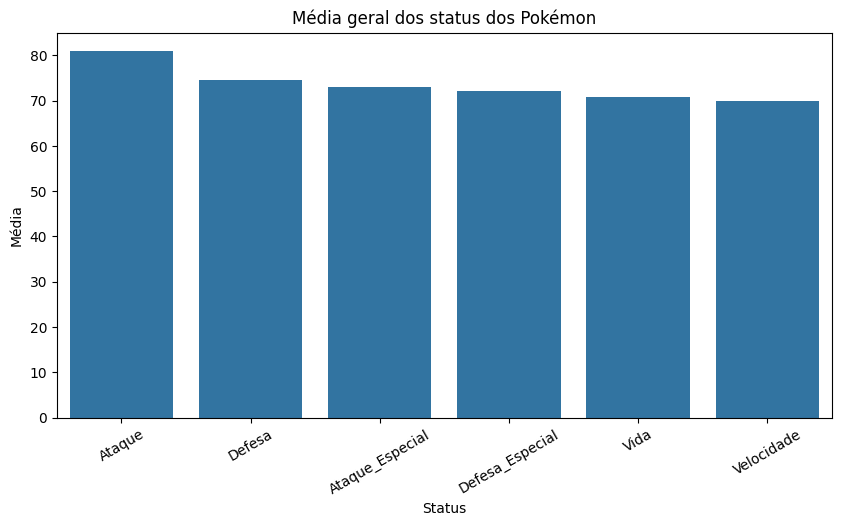

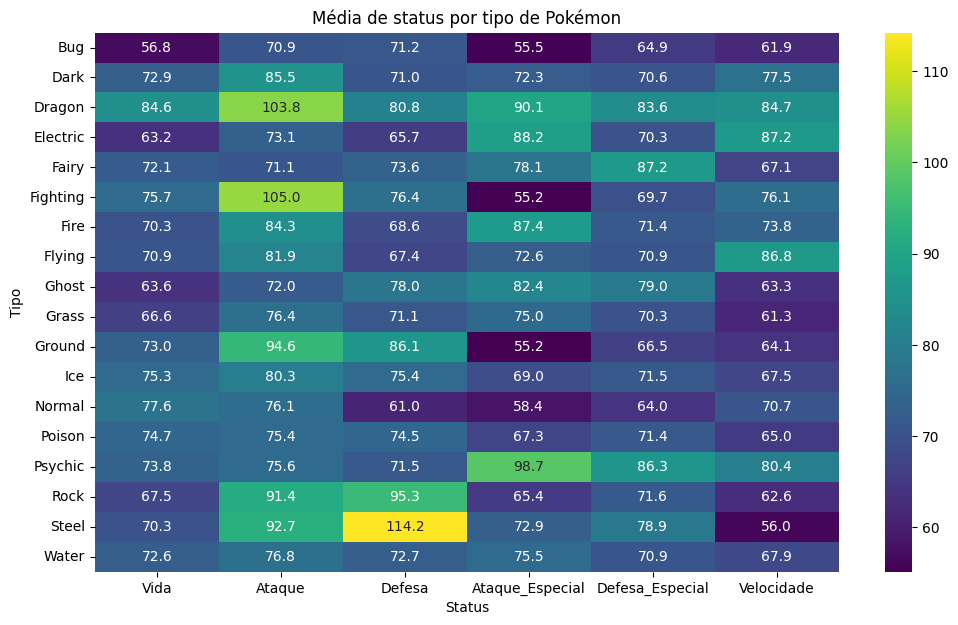

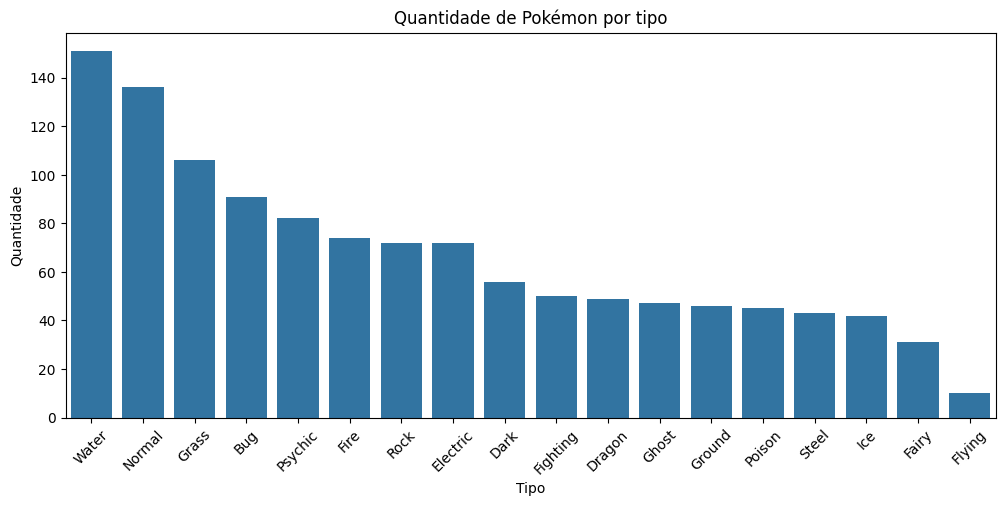

In [ ]:
# 1. Status médio geral

status = ["Vida", "Ataque", "Defesa", "Ataque_Especial",
          "Defesa_Especial", "Velocidade"]

media_status = dataset_ia[status].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=media_status.index, y=media_status.values)

plt.title("Média geral dos status dos Pokémon")
plt.xlabel("Status")
plt.ylabel("Média")
plt.xticks(rotation=30)
plt.show()


# 2. Média de status por tipagem

media_tipos = dataset_ia.groupby("Tipo_1")[status].mean()

plt.figure(figsize=(12, 7))
sns.heatmap(media_tipos, annot=True, fmt=".1f", cmap="viridis")

plt.title("Média de status por tipo de Pokémon")
plt.xlabel("Status")
plt.ylabel("Tipo")
plt.show()


# 3. Quantidade de Pokémon por tipo

quantidade_tipos = dataset_ia["Tipo_1"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(x=quantidade_tipos.index, y=quantidade_tipos.values)

plt.title("Quantidade de Pokémon por tipo")
plt.xlabel("Tipo")
plt.ylabel("Quantidade")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# 1. Previsões do dataset

x_completo = previsores.copy()

x_completo[status] = normalizador.transform(
    x_completo[status]
)

previsoes_completas = modelo.predict(x_completo)

dataset_ia["Perfil_Previsto"] = encoder.inverse_transform(
    np.argmax(previsoes_completas, axis=1)
)


# Normalização das pontuações

dataset_ia["Total_Normalizado"] = (
    (dataset_ia["Total"] - dataset_ia["Total"].min()) /
    (dataset_ia["Total"].max() - dataset_ia["Total"].min())
)

dataset_ia["Defesa_Normalizada"] = (
    (dataset_ia["Pontuacao_Defensiva"] - dataset_ia["Pontuacao_Defensiva"].min()) /
    (dataset_ia["Pontuacao_Defensiva"].max() - dataset_ia["Pontuacao_Defensiva"].min())
)

# Pontuação para seleção dos Pokémon

dataset_ia["Pontuacao_Final"] = (
    dataset_ia["Total_Normalizado"] * 0.6
    + dataset_ia["Defesa_Normalizada"] * 0.4
)


# 2. Montagem dos times

def montar_time(nome, quantidades):

    selecionados = []

    for perfil, quantidade in quantidades.items():

        candidatos = dataset_ia[
          dataset_ia["Perfil_Previsto"] == perfil
      ].sort_values("Pontuacao_Final", ascending=False)

        selecionados.append(candidatos.head(quantidade))

    time = pd.concat(selecionados).drop_duplicates("Nome")

    if len(time) < 6:
        restantes = dataset_ia[
            ~dataset_ia["Nome"].isin(time["Nome"])
        ].sort_values("Pontuacao_Final", ascending=False)

        time = pd.concat([
            time,
            restantes.head(6 - len(time))
        ])

    time = time.head(6).copy()
    time["Time"] = nome

    return time


time_equilibrado = montar_time("Equilibrado", {
    "Ofensivo_Fisico": 2,
    "Ofensivo_Especial": 2,
    "Defensivo": 2
})

time_ofensivo = montar_time("Ofensivo", {
    "Ofensivo_Fisico": 3,
    "Ofensivo_Especial": 2,
    "Defensivo": 1
})

time_defensivo = montar_time("Defensivo", {
    "Defensivo": 4,
    "Ofensivo_Fisico": 1,
    "Ofensivo_Especial": 1
})

times = pd.concat([
    time_equilibrado,
    time_ofensivo,
    time_defensivo
])

print(times[
    ["Time", "Nome", "Tipo_1", "Tipo_2",
     "Perfil_Previsto", "Total",
     "Fraquezas", "Resistencias",
     "Imunidades", "Pontuacao_Final"]
])

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
             Time                      Nome    Tipo_1   Tipo_2  \
1063  Equilibrado      Zacian Crowned Sword     Fairy    Steel   
377   Equilibrado               Mega Aggron     Steel   Nenhum   
593   Equilibrado        Dialga Origin Form     Steel   Dragon   
592   Equilibrado                    Dialga     Steel   Dragon   
1067  Equilibrado       Eternamax Eternatus    Poison   Dragon   
1065  Equilibrado  Zamazenta Crowned Shield  Fighting    Steel   
1063     Ofensivo      Zacian Crowned Sword     Fairy    Steel   
377      Ofensivo               Mega Aggron     Steel   Nenhum   
460      Ofensivo            Mega Metagross     Steel  Psychic   
593      Ofensivo        Dialga Origin Form     Steel   Dragon   
592      Ofensivo                    Dialga     Steel   Dragon   
1067     Ofensivo       Eternamax Eternatus    Poison   Dragon   
1067    Defensivo       Eternamax Eternatus    Poison   Dragon   
1065    Defensivo  Zamazenta Crowned

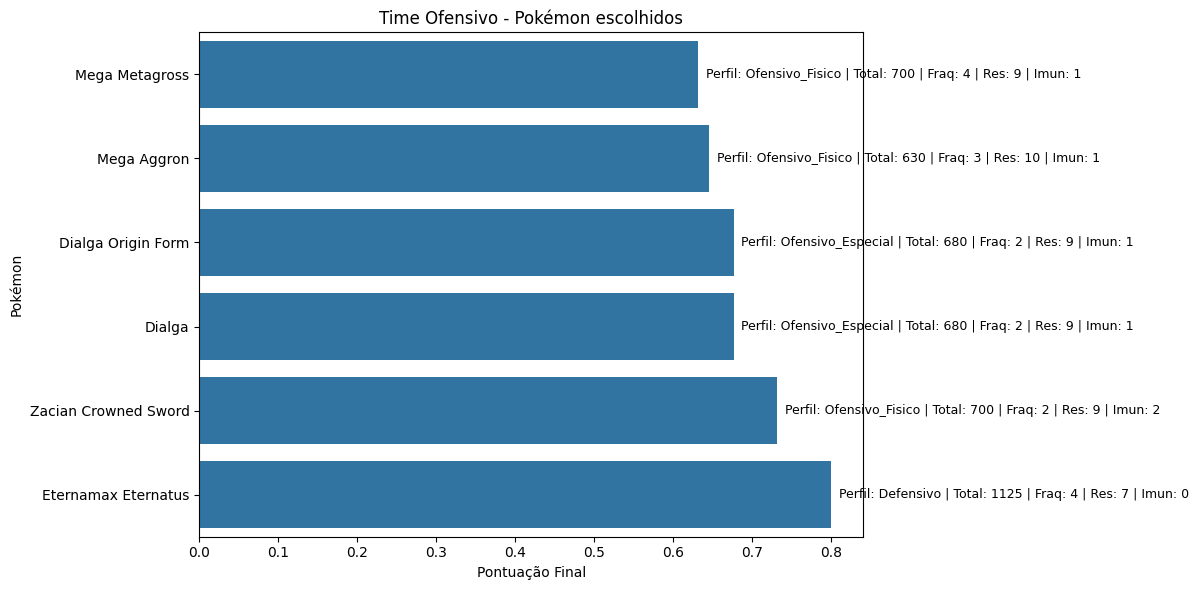

In [ ]:
## Montagem gráfica do time OFENSIVO!

time_ofensivo_grafico = times[
    times["Time"] == "Ofensivo"
].sort_values("Pontuacao_Final", ascending=True)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=time_ofensivo_grafico,
    x="Pontuacao_Final",
    y="Nome"
)

plt.title("Time Ofensivo - Pokémon escolhidos")
plt.xlabel("Pontuação Final")
plt.ylabel("Pokémon")

for i, (_, linha) in enumerate(time_ofensivo_grafico.iterrows()):
    texto = (
        f'Perfil: {linha["Perfil_Previsto"]} | '
        f'Total: {linha["Total"]} | '
        f'Fraq: {linha["Fraquezas"]} | '
        f'Res: {linha["Resistencias"]} | '
        f'Imun: {linha["Imunidades"]}'
    )
    plt.text(
        linha["Pontuacao_Final"] + 0.01,
        i,
        texto,
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

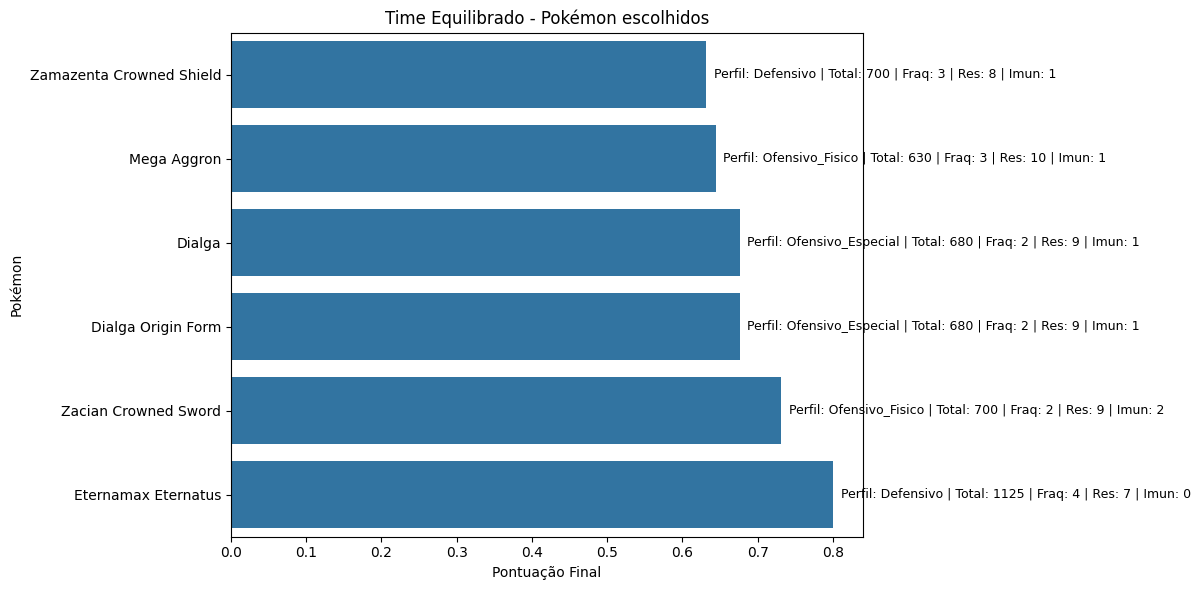

In [ ]:
## Montagem gráfica do time OFENSIVO!

time_equilibrado_grafico = times[
    times["Time"] == "Equilibrado"
].sort_values("Pontuacao_Final", ascending=True)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=time_equilibrado_grafico,
    x="Pontuacao_Final",
    y="Nome"
)

plt.title("Time Equilibrado - Pokémon escolhidos")
plt.xlabel("Pontuação Final")
plt.ylabel("Pokémon")

for i, (_, linha) in enumerate(time_equilibrado_grafico.iterrows()):
    texto = (
        f'Perfil: {linha["Perfil_Previsto"]} | '
        f'Total: {linha["Total"]} | '
        f'Fraq: {linha["Fraquezas"]} | '
        f'Res: {linha["Resistencias"]} | '
        f'Imun: {linha["Imunidades"]}'
    )
    plt.text(
        linha["Pontuacao_Final"] + 0.01,
        i,
        texto,
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

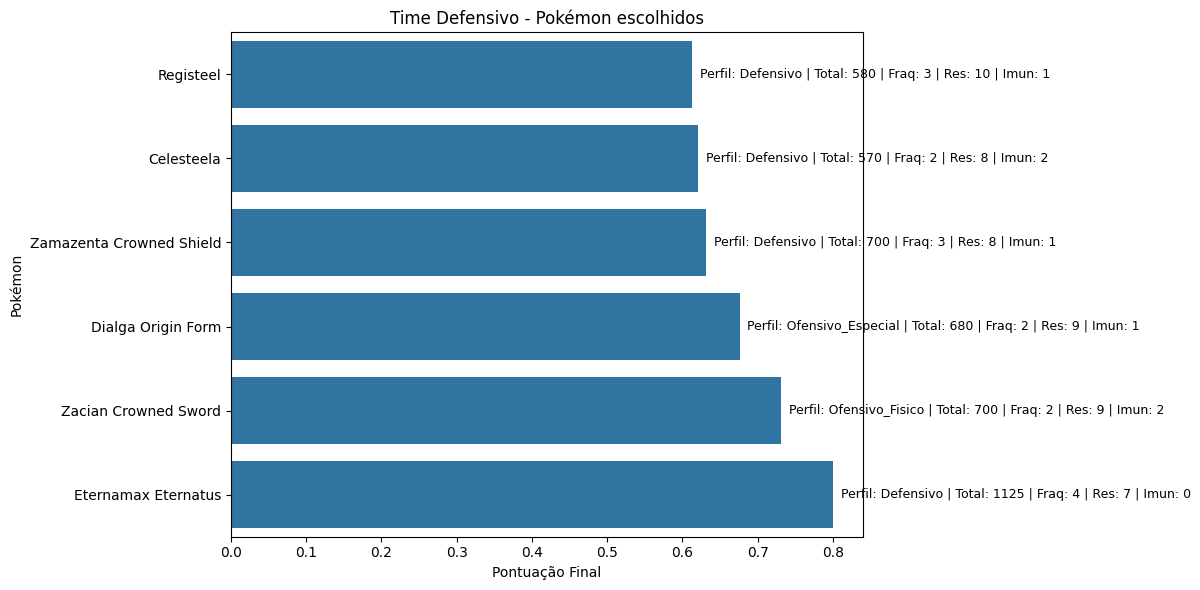

In [ ]:
## Montagem gráfica do time OFENSIVO!


time_defensivo_grafico = times[
    times["Time"] == "Defensivo"
].sort_values("Pontuacao_Final", ascending=True)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=time_defensivo_grafico,
    x="Pontuacao_Final",
    y="Nome"
)

plt.title("Time Defensivo - Pokémon escolhidos")
plt.xlabel("Pontuação Final")
plt.ylabel("Pokémon")

for i, (_, linha) in enumerate(time_defensivo_grafico.iterrows()):
    texto = (
        f'Perfil: {linha["Perfil_Previsto"]} | '
        f'Total: {linha["Total"]} | '
        f'Fraq: {linha["Fraquezas"]} | '
        f'Res: {linha["Resistencias"]} | '
        f'Imun: {linha["Imunidades"]}'
    )
    plt.text(
        linha["Pontuacao_Final"] + 0.01,
        i,
        texto,
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

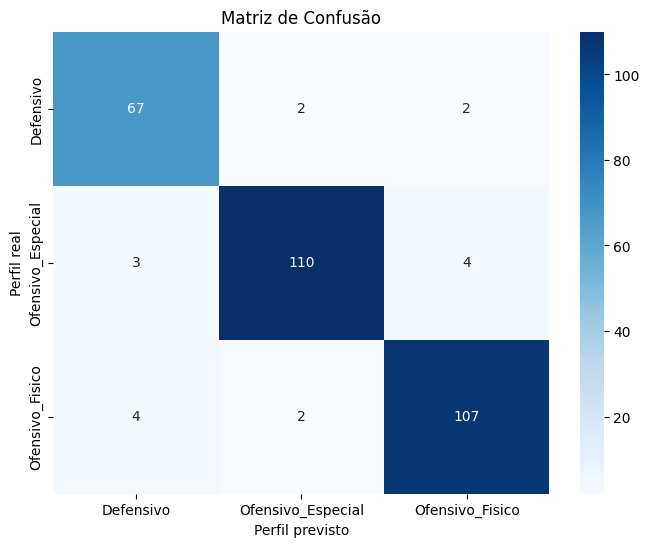

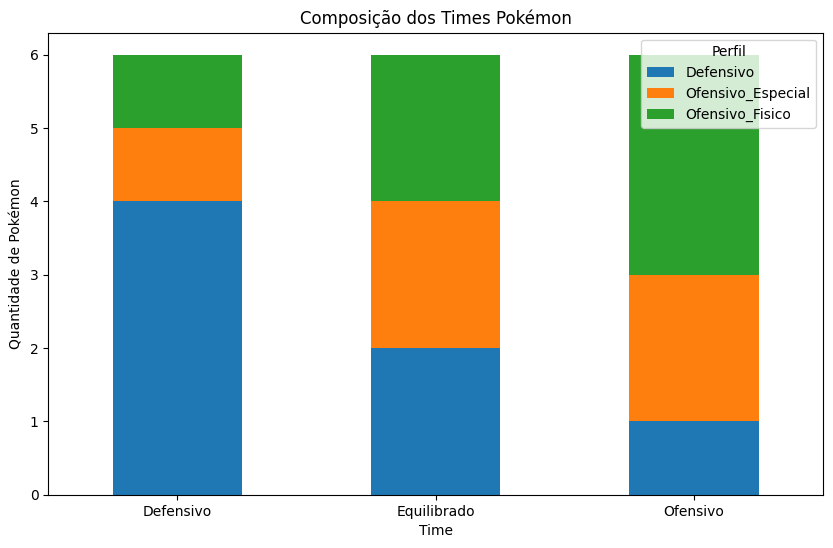

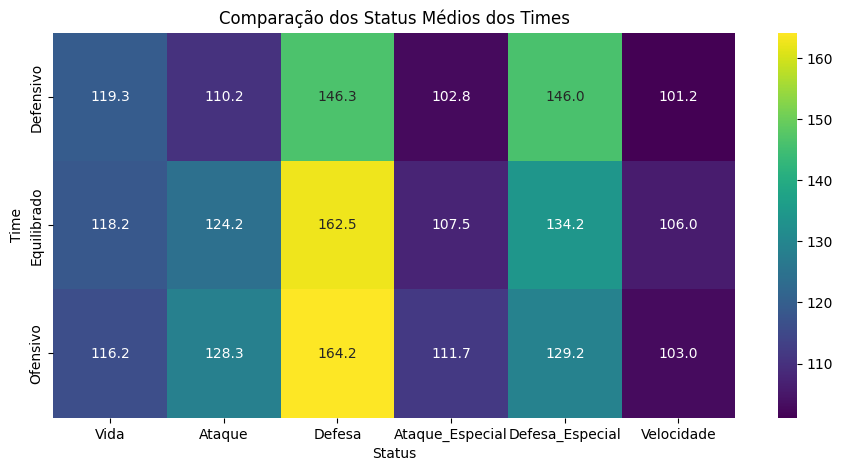

In [ ]:
# 1. Matriz de confusão

plt.figure(figsize=(8, 6))

sns.heatmap(
    confusao,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title("Matriz de Confusão")
plt.xlabel("Perfil previsto")
plt.ylabel("Perfil real")
plt.show()


# 2. Composição dos times

composicao = pd.crosstab(
    times["Time"],
    times["Perfil_Previsto"]
).reindex(columns=encoder.classes_, fill_value=0)

composicao.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Composição dos Times Pokémon")
plt.xlabel("Time")
plt.ylabel("Quantidade de Pokémon")
plt.xticks(rotation=0)
plt.legend(title="Perfil")
plt.show()


# 3. Média dos status por time

media_times = times.groupby("Time")[status].mean()

plt.figure(figsize=(11, 5))

sns.heatmap(
    media_times,
    annot=True,
    fmt=".1f",
    cmap="viridis"
)

plt.title("Comparação dos Status Médios dos Times")
plt.xlabel("Status")
plt.ylabel("Time")
plt.show()

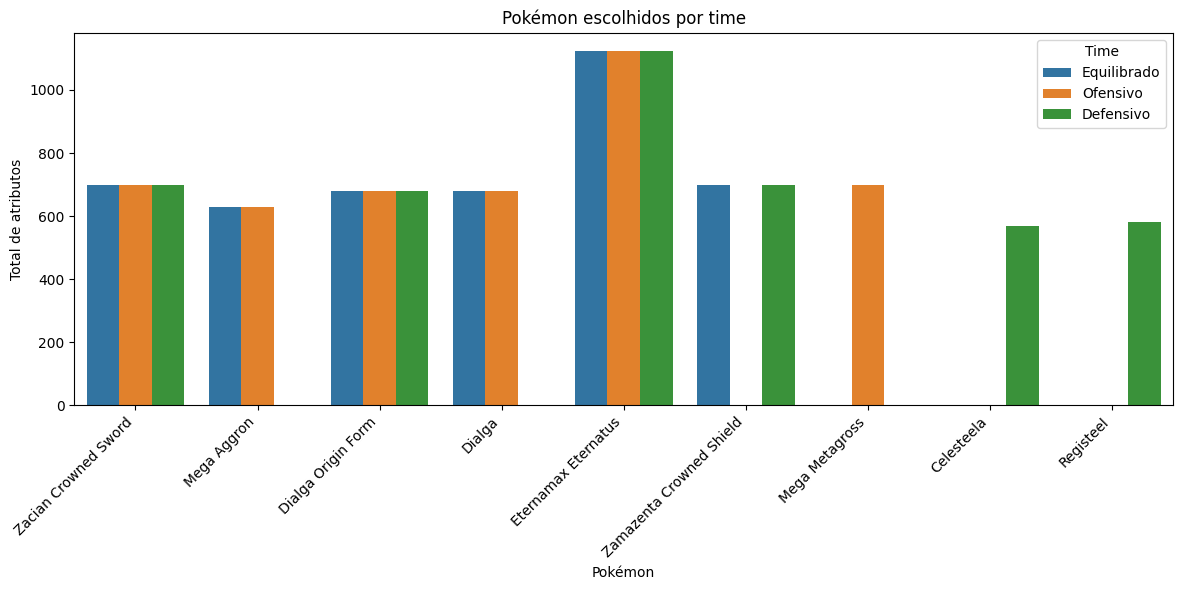

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=times,
    x="Nome",
    y="Total",
    hue="Time"
)

plt.title("Pokémon escolhidos por time")
plt.xlabel("Pokémon")
plt.ylabel("Total de atributos")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Time")
plt.tight_layout()
plt.show()

In [ ]:
modelo.save("pokemon_modelo.keras")